In [54]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import geopandas as gpd
import osmnx as ox
import shapely
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.spatial import cKDTree

# --- Parámetros en un solo sitio: si cambias algo, lo cambias aquí ---
CRS = 32633                      # UTM 33N: unidades en metros, necesario para medir distancias
STEP = 50                        # separación de la malla en metros (50 m = bordes más suaves)
FAR_M = 1000                     # umbral para "lejos de una estación"
BG = "#0b1020"                   # color de fondo del mapa

DATA = Path("../data/external")  # pathlib evita el problema de "\\" en Windows
OUT = Path("../outputs")
OUT.mkdir(exist_ok=True)         # crea la carpeta de salida si no existe

In [55]:
bz = gpd.read_file(DATA / "BEZIRKSGRENZEOGD.zip").to_crs(CRS)

# Validación: Viena tiene 23 distritos. Si no salen 23, el archivo no es el esperado
# (esto es lo que te pasó con el mapa de toda Austria).
assert len(bz) == 23, f"Se esperaban 23 distritos y hay {len(bz)}"

limite = bz.union_all()          # un único polígono con toda la ciudad
shapely.prepare(limite)          # lo "prepara" una vez: los tests de pertenencia son mucho más rápidos

np.True_

In [56]:
gdf = ox.features_from_place("Vienna, Austria", tags={"amenity": "charging_station"}).to_crs(CRS)
gdf["geometry"] = gdf.geometry.centroid     # OSM mezcla nodos y polígonos: todo a punto

# Filtro de seguridad: quedarse solo con estaciones dentro del límite oficial.
# Puede quitar alguna estación del borde; imprime cuántas para que quede registrado.
n0 = len(gdf)
gdf = gdf[shapely.contains_xy(limite, gdf.geometry.x, gdf.geometry.y)].copy()
print(f"Estaciones: {n0} descargadas -> {len(gdf)} dentro de Viena")

Estaciones: 779 descargadas -> 779 dentro de Viena


In [57]:
# Columnas con la potencia de cada tipo de conector (p. ej. "socket:type2:output")
out_cols = [c for c in gdf.columns if c.startswith("socket:") and c.endswith(":output")]

# Comprobación de unidades: mira que todo sea "22 kW", "50", etc. y no "22000 W"
print(gdf[out_cols].stack().value_counts().head(15))

def max_kw(row):
    """Potencia máxima (kW) entre todos los conectores de una estación."""
    vals = []
    for v in row:
        # findall con un patrón numérico estricto; evita capturar un "." suelto
        # y funciona con valores como "22;11" (varias potencias en un solo campo)
        vals += [float(x) for x in re.findall(r"\d+(?:\.\d+)?", str(v))]
    return max(vals) if vals else np.nan

gdf["kw"] = gdf[out_cols].apply(max_kw, axis=1)

# Etiquetas ya en inglés: así no necesitas un diccionario de traducción después
labels = ["Normal (≤22 kW)", "Fast (22–100 kW)", "Ultra-fast (>100 kW)"]
gdf["speed"] = (pd.cut(gdf["kw"], bins=[0, 22, 100, np.inf], labels=labels)
                  .astype(object).fillna("Unknown"))

print(gdf["speed"].value_counts())

11 kW           414
3.7 kW           70
50 kW            30
22 kW            17
11               10
44 kW            10
50kW              8
11 kW;3.7 kW      6
11kW              6
22 kW;11 kW       5
43 kW             5
300 kW            4
250 kW            4
150 kW            4
43kW              3
Name: count, dtype: int64
speed
Normal (≤22 kW)         458
Unknown                 268
Ultra-fast (>100 kW)     27
Fast (22–100 kW)         26
Name: count, dtype: int64


In [58]:
X = np.column_stack([gdf.geometry.x, gdf.geometry.y])   # coordenadas de estaciones (m)

# 1) Malla regular sobre la caja que envuelve a Viena
minx, miny, maxx, maxy = bz.total_bounds
xs = np.arange(minx, maxx, STEP)
ys = np.arange(miny, maxy, STEP)
XX, YY = np.meshgrid(xs, ys)
px, py = XX.ravel(), YY.ravel()

# 2) Qué puntos de la malla caen dentro de la ciudad (rápido, con arrays; sin crear objetos Point)
inside = shapely.contains_xy(limite, px, py)

# 3) Distancia a la estación más cercana, solo para los puntos interiores
dist, _ = cKDTree(X).query(np.column_stack([px[inside], py[inside]]))

# 4) Devolver el resultado a la forma de la malla; fuera de Viena = NaN (queda transparente)
D = np.full(px.shape, np.nan)
D[inside] = dist
D = D.reshape(XX.shape)

In [59]:
pct_far = (dist > FAR_M).mean() * 100
print(f"Mediana: {np.median(dist):.0f} m | P90: {np.percentile(dist, 90):.0f} m | "
      f"máx: {dist.max():.0f} m | >{FAR_M} m: {pct_far:.0f}%")

# Para el panel de velocidad: ¿dónde están las rápidas respecto al centro?
centro = gpd.GeoSeries(gpd.points_from_xy([16.3726], [48.2082]), crs=4326).to_crs(CRS).iloc[0]  # Stephansplatz
gdf["km_centro"] = gdf.distance(centro) / 1000
med = gdf.groupby("speed")["km_centro"].median().round(1)
print(med)

Mediana: 531 m | P90: 2399 m | máx: 7976 m | >1000 m: 31%
speed
Fast (22–100 kW)        6.3
Normal (≤22 kW)         4.4
Ultra-fast (>100 kW)    8.1
Unknown                 4.3
Name: km_centro, dtype: float64


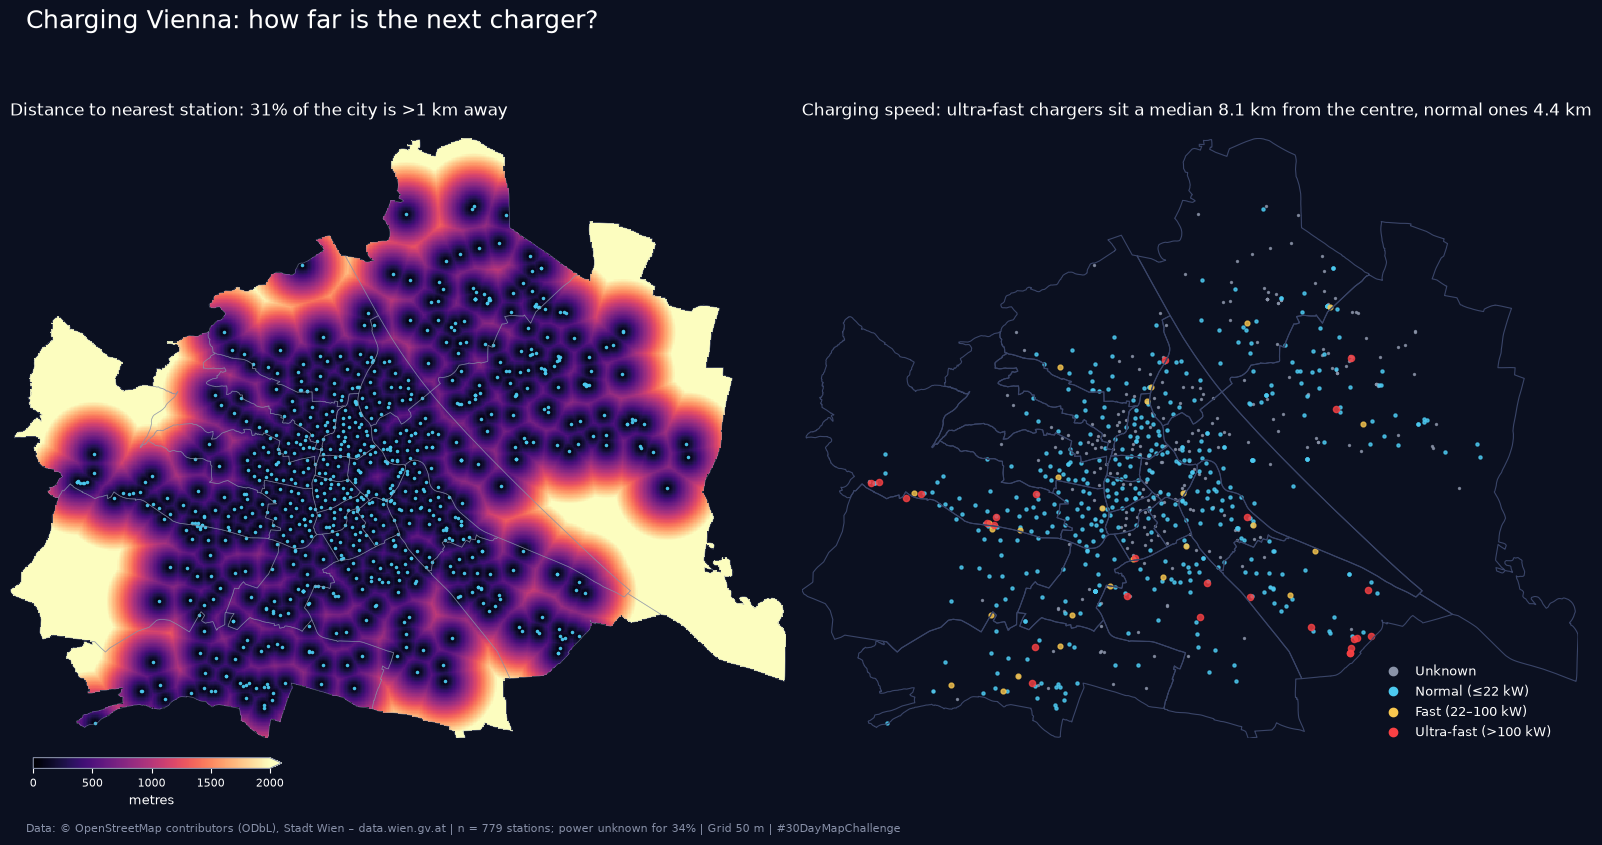

In [70]:
colores = {"Unknown": "#8a93a8", "Normal (≤22 kW)": "#4cc9f0",
           "Fast (22–100 kW)": "#f9c74f", "Ultra-fast (>100 kW)": "#f94144"}
tam = {"Unknown": 2, "Normal (≤22 kW)": 5, "Fast (22–100 kW)": 12, "Ultra-fast (>100 kW)": 20}

fig, axes = plt.subplots(1, 2, figsize=(16, 8.5), facecolor=BG)

# ---------- Panel izquierdo: distancia a la estación más cercana ----------
ax = axes[0]
ax.set_facecolor(BG)
# vmax=2000: todo lo que pase de 2 km usa el mismo color; así el contraste se ve en la zona útil
mesh = ax.pcolormesh(XX, YY, D, cmap="magma", vmin=0, vmax=2000, shading="auto")
bz.boundary.plot(ax=ax, color="#8890a8", linewidth=0.5, alpha=0.6)   # distritos
gdf.plot(ax=ax, color="#4cc9f0", markersize=2.5, alpha=0.9)          # estaciones encima
ax.set_title(f"Distance to nearest station: {pct_far:.0f}% of the city is >1 km away",
             color="white", fontsize=12, loc="left")

# Barra de color pequeña dentro del mapa, en la esquina inferior izquierda
cax = ax.inset_axes([0.03, -0.05, 0.32, 0.018]) # x, y, width, height
cb = fig.colorbar(mesh, cax=cax, orientation="horizontal", extend="max")
cb.set_label("metres", color="white", fontsize=9)
cb.ax.tick_params(colors="white", labelsize=8)
cb.outline.set_edgecolor("#8890a8")

# ---------- Panel derecho: velocidad de carga ----------
ax = axes[1]
ax.set_facecolor(BG)
bz.boundary.plot(ax=ax, color="#3a4568", linewidth=0.8)
for s, col in colores.items():                     # el orden del dict dibuja las rápidas encima
    gdf[gdf["speed"] == s].plot(ax=ax, color=col, markersize=tam[s], alpha=0.8)
ax.set_title(f"Charging speed: ultra-fast chargers sit a median {med['Ultra-fast (>100 kW)']} km "
             f"from the centre, normal ones {med['Normal (≤22 kW)']} km",
             color="white", fontsize=12, loc="left")
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=c, label=l) for l, c in colores.items()],
          loc="lower right", frameon=False, labelcolor="white", bbox_to_anchor=(0.98, -0.02), fontsize=9)

# ---------- Común a los dos paneles ----------
for ax in axes:
    ax.set_xlim(minx, maxx); ax.set_ylim(miny, maxy)   # mismo encuadre: paneles del mismo tamaño
    ax.set_aspect("equal"); ax.set_axis_off()

fig.suptitle("Charging Vienna: how far is the next charger?",
             color="white", fontsize=18, x=0.02, ha="left")

# Pie en dos líneas: fuente + advertencia de interpretación
# fig.text(0.02, 0.035,
#          "Light areas are often forest, parkland, river or industry (Wienerwald, Lobau, Danube): "
#          "distance alone does not imply unmet demand.",
#          color="#c4c9d8", fontsize=9)
fig.text(0.02, 0.012,
         f"Data: © OpenStreetMap contributors (ODbL), Stadt Wien – data.wien.gv.at | "
         f"n = {len(gdf)} stations; power unknown for {(gdf['speed']=='Unknown').mean():.0%} | "
         f"Grid {STEP} m | #30DayMapChallenge",
         color="#8890a8", fontsize=8)

fig.subplots_adjust(left=0.01, right=0.99, top=0.88, bottom=0.07, wspace=0.02)
fig.savefig(OUT / "day01_ev_charging_vienna.png", dpi=300, facecolor=BG, bbox_inches="tight")
plt.show()